# Our fixed-BVOC runs next to Tang et al. (2023), Figs. 1, 2 and 5

Tang, J. et al. *High-latitude vegetation changes will determine future plant volatile impacts on atmospheric organic aerosols.* npj Clim. Atmos. Sci. 6, 147 (2023). Our LCC land cover comes from the same LPJ-GUESS set-up (GFDL-ESM4, SSP5-8.5, 2071–2100 − 1971–2000), so the question is: **do we see the same spatial pattern and the same size of vegetation effect?**

**How the experiments line up.** Tang's TM5 runs keep the 2009 weather and change only the BVOC emissions and vegetation. Our fixed-BVOC (fBVOC) runs in the FUT background do the same: all runs are nudged to the same winds and only the prescribed emissions differ.

| Column | Tang (Fig. 5, CanESM5 SSP585) | Ours (FUT background, all 19 MEGAN species prescribed) |
|---|---|---|
| 1 | **standard**: 2100 − 2009 emissions (vegetation + climate + CO₂) | `LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlPD` |
| 2 | **noVegDym**: climate on emissions, vegetation fixed | `LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD` |
| 3 | **standard − noVegDym** (vegetation effect; not a panel in Tang) | `LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlFUT` |

**Differences to keep in mind**
- **Vegetation.** Tang's "vegetation change" includes LPJ-GUESS productivity and LAI. Ours changes only `PCT_NAT_PFT` in the CLM surfdata; LAI comes from CLM.
- **CO₂ inhibition.** CLM-MEGAN applies it to **isoprene only** (`components/clm/src/biogeochem/VOCEmissionMod.F90:435`); LPJ-GUESS applies it to monoterpenes too.
- **Future climate.** Our FUT emissions come from NorESM2 SSP5-8.5 (2100 forcing, NORBC sea surface) with PD nudging winds; Tang's from bias-corrected CanESM5 (Fig. 5) or GFDL-ESM4 (Fig. 1, our LCC source).
- **Emissions are a climatology** (2001–2014 of the source run, the same every year), so the emission rows have no interannual spread and get **no significance test**. The aerosol rows (SOA, AOD, CCN) vary year to year through the nudged weather and are tested.
- **Optical depth.** We have no SOA-only optical depth; the **SOA column burden** (interstitial + cloud-borne) stands in for Tang's OD550soa. `AOD_VIS` (aerosol optical depth over 0.442–0.625 µm, the band containing 550 nm) stands in for OD550aer. (`AOD_VIS` is all fill values in our output: OsloAero does not write it.)
- **CCN.** `CCN7` = CCN at S = 1.0 %, lowest model level: the same quantity as Tang's CCN1.0.
- **Units and ratios as in Tang:** emissions in mgC m⁻² yr⁻¹; aerosol rows as the ratio (case1 − case2) / case2 of the 25-year means (a fraction, not %).
- Hatching = **not** significant (paired yearly t-test, FDR α = 0.10 over ≥45°N; project convention).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

REPO = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
sys.path.insert(0, str(REPO / "src"))
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.plotting import palette as pal
from boreal_forest_expansion.analysis.stats import cellwise_pvalue, fdr_mask

Y0, Y1 = 2001, 2025
NYR = Y1 - Y0 + 1
OUT = REPO / "diagnostics" / "tang2023-comparison" / "tang2023_comparison_outputs"
OUT.mkdir(parents=True, exist_ok=True)

EXTENT_LAT = 40.0   # map edge
MEAN_LAT = 45.0     # regional means and FDR region
FDR_ALPHA = 0.10

COLUMNS = {   # key: (case1, case2, title)
    "std":   ("LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlPD", "\"standard\"\nlccFUT − ctrlPD"),
    "noveg": ("LCC_FUT_fBVOCctrlFUT", "LCC_FUT_fBVOCctrlPD", "\"noVegDym\"\nctrlFUT − ctrlPD"),
    "veg":   ("LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlFUT", "vegetation effect\nlccFUT − ctrlFUT"),
}
EXTRA_RUNS = ["LCC_PD_fBVOClccPD", "LCC_PD_fBVOCctrlPD"]   # PD vegetation effect on emissions (section 5b)
RUNS = sorted({r for c1, c2, _ in COLUMNS.values() for r in (c1, c2)} | set(EXTRA_RUNS))
print(RUNS)

['LCC_FUT_fBVOCctrlFUT', 'LCC_FUT_fBVOCctrlPD', 'LCC_FUT_fBVOClccFUT', 'LCC_PD_fBVOCctrlPD', 'LCC_PD_fBVOClccPD']


## 1. Yearly fields of every run

| Row | Variable | Shown as |
|---|---|---|
| ISO emission | `SFISOP` × 60.05/68.12 (carbon fraction of C₅H₈) | difference, mgC m⁻² yr⁻¹ |
| MT emission | `SFMTERP` × 120.1/136.2 (C₁₀H₁₆) | difference, mgC m⁻² yr⁻¹ |
| SOA_surf | `SOA_A1 + SOA_NA`, lowest level | ratio |
| SOA burden (≈ OD550soa) | `cb_SOA_A1 + cb_SOA_NA + cb_SOA_A1_OCW + cb_SOA_NA_OCW` | ratio |
| AOD (≈ OD550aer) | `AOD_VIS` | ratio |
| CCN1.0 | `CCN7`, lowest level | ratio |

`SF*` is everything the atmosphere receives (prescribed MEGAN + biomass burning).

**Cache.** The fields above are copied once into one small file per run in `tang2023_comparison_outputs/cache/` (symlink to `/cluster/work/users/adelez/boreal-caches/…`; 3-D fields keep only the lowest level). Every read is **retried**: on 2026-11-16 NIRD gave random `NetCDF: HDF error` reads on the multi-GB SOA files (a different variable failed each time, so the files are fine). Set `REBUILD_CACHE = True` after changing variables or inputs.

In [2]:
import time
import netCDF4 as nc

REBUILD_CACHE = False
CACHE = OUT / "cache"
NEED = {   # class: variables; 4-D ones -> lowest level, stored as <name>_sfc
    "BVOC": ["SFISOP", "SFMTERP", "gw", "LANDFRAC"],
    "SOA": ["SOA_A1", "SOA_NA", "cb_SOA_A1", "cb_SOA_NA", "cb_SOA_A1_OCW", "cb_SOA_NA_OCW", "CCN7"],
    "AEROPT": ["AOD_VIS"],
}

def read_retry(path, var, tries=30):
    for i in range(tries):
        try:
            with nc.Dataset(path) as d:
                x = d[var]
                x.set_auto_mask(False)
                a = x[:, -1] if x.ndim == 4 else x[:]
                dims = [dd for k, dd in enumerate(x.dimensions) if not (x.ndim == 4 and k == 1)]
                return np.asarray(a), dims
        except (RuntimeError, OSError) as e:
            print(f"  retry {i + 1} {path.name} {var}: {e}")
            time.sleep(5)
    raise RuntimeError(f"gave up reading {var} from {path}")

def build_cache(run):
    out = CACHE / f"{run}_tang_fields_{Y0}-{Y1}.nc"
    if out.exists() and not REBUILD_CACHE:
        with xr.open_dataset(out) as old:   # a cache missing a variable (NEED changed) is rebuilt
            if all((v + "_sfc" if v in ("SOA_A1", "SOA_NA", "CCN7") else v) in old for vs in NEED.values() for v in vs):
                return out
        print("cache lacks variables, rebuilding", out.name)
    ref = fm.filename(run, "BVOC", Y0, Y1)
    tb, _ = read_retry(ref, "time_bnds")
    with xr.open_dataset(ref, decode_times=False) as r:
        coords = {k: r[k].load() for k in ("time", "lat", "lon")}
    ds = xr.Dataset(coords=coords)
    ds["time_bnds"] = (("time", "nbnd"), tb, {"units": coords["time"].attrs.get("units"),
                                              "calendar": coords["time"].attrs.get("calendar")})
    ds["time"].attrs["bounds"] = "time_bnds"
    for cls, vs in NEED.items():
        for v in vs:
            a, dims = read_retry(fm.filename(run, cls, Y0, Y1), v)
            ds[v + "_sfc" if v in ("SOA_A1", "SOA_NA", "CCN7") else v] = (tuple(dims), a)
    ds.attrs.update(alias=run, source=str(fm.POSTPROCESSED_DIR), years=f"{Y0}-{Y1}")
    tmp = out.with_suffix(".tmp")
    ds.to_netcdf(tmp)
    tmp.rename(out)
    return out

CACHE.mkdir(parents=True, exist_ok=True)
cached = {run: xr.open_dataset(build_cache(run)) for run in RUNS}
for run, ds in cached.items():
    print(run, dict(ds.sizes), "time", str(ds["time"].values[0]), "→", str(ds["time"].values[-1]))

  retry 1 LCC_PD_fBVOClccPD_atm_SOA_2001-2025.nc SOA_A1: NetCDF: HDF error
LCC_FUT_fBVOCctrlFUT {'time': 300, 'nbnd': 2, 'lat': 96, 'lon': 144} time 2001-01-16 12:00:00 → 2025-12-16 12:00:00
LCC_FUT_fBVOCctrlPD {'time': 300, 'nbnd': 2, 'lat': 96, 'lon': 144} time 2001-01-16 12:00:00 → 2025-12-16 12:00:00
LCC_FUT_fBVOClccFUT {'time': 300, 'nbnd': 2, 'lat': 96, 'lon': 144} time 2001-01-16 12:00:00 → 2025-12-16 12:00:00
LCC_PD_fBVOCctrlPD {'time': 300, 'nbnd': 2, 'lat': 96, 'lon': 144} time 2001-01-16 12:00:00 → 2025-12-16 12:00:00
LCC_PD_fBVOClccPD {'time': 300, 'nbnd': 2, 'lat': 96, 'lon': 144} time 2001-01-16 12:00:00 → 2025-12-16 12:00:00


In [3]:
SEC_YR = 86400 * 365
C_ISOP, C_MTERP = 5 * 12.011 / 68.12, 10 * 12.011 / 136.24

ROWS = {   # key: (function(ds) -> monthly DataArray (time, lat, lon), label, units, kind)
    "ISO":  (lambda ds: ds["SFISOP"] * 1e6 * SEC_YR * C_ISOP, "ISO emission", "mgC m$^{-2}$ yr$^{-1}$", "diff"),
    "MT":   (lambda ds: ds["SFMTERP"] * 1e6 * SEC_YR * C_MTERP, "MT emission", "mgC m$^{-2}$ yr$^{-1}$", "diff"),
    "SOAs": (lambda ds: ds["SOA_A1_sfc"] + ds["SOA_NA_sfc"], "SOA$_{surf}$", "–", "ratio"),
    "SOAb": (lambda ds: ds["cb_SOA_A1"] + ds["cb_SOA_NA"] + ds["cb_SOA_A1_OCW"] + ds["cb_SOA_NA_OCW"],
             "SOA burden\n(≈ OD550$_{soa}$)", "–", "ratio"),
    "AOD":  (lambda ds: ds["AOD_VIS"], "AOD vis\n(≈ OD550$_{aer}$)", "–", "ratio"),
    "CCN":  (lambda ds: ds["CCN7_sfc"], "CCN1.0", "–", "ratio"),
}

yearly = {}   # (run, row) -> (year, lat, lon)
for run, ds in cached.items():
    for key, (f, *_ ) in ROWS.items():
        yearly[run, key] = fm.annual_mean(f(ds), ds).load()
print({k: dict(v.sizes) for k, v in list(yearly.items())[:1]})

{('LCC_FUT_fBVOCctrlFUT', 'ISO'): {'year': 25, 'lat': 96, 'lon': 144}}


In [4]:
mask_ds = xr.open_dataset(REPO / "diagnostics" / "lcc-modified-cells" / "modified_cells.nc")
modified = mask_ds["modified"].astype(bool)
# the mask's lat/lon differ from the model's by float noise (max 1.7e-13 deg): check, then use the model's
_ref = next(iter(cached.values()))
assert np.allclose(modified["lat"], _ref["lat"], atol=1e-9) and np.allclose(modified["lon"], _ref["lon"], atol=1e-9)
modified = modified.assign_coords(lat=_ref["lat"].values, lon=_ref["lon"].values)
region = modified["lat"] >= MEAN_LAT

def wmean(da, where=None):
    w = np.cos(np.deg2rad(da["lat"])) * xr.ones_like(da)
    if where is not None:
        w = w.where(where, 0)
    return float((da * w).sum() / w.sum())

def column_fields(key, col):
    # mean map, significance map (True = NOT significant, for hatching), regional value
    c1, c2, _ = COLUMNS[col]
    a, b = yearly[c1, key], yearly[c2, key]
    d = a - b
    kind = ROWS[key][3]
    if kind == "diff":
        m = d.mean("year")
        reg = wmean(m, region)
        notsig = None   # prescribed climatology: no interannual spread
    else:
        bm = b.mean("year")
        m = d.mean("year") / bm
        reg = wmean(d.mean("year"), region) / wmean(bm, region)
        p = cellwise_pvalue(d)
        sig = fdr_mask(p, alpha=FDR_ALPHA, within=d["lat"] >= MEAN_LAT)
        notsig = (~sig) & np.isfinite(p) & (d["lat"] >= MEAN_LAT)
    return m, notsig, reg

# check: emission rows really are identical every year (climatology)
for run in RUNS:
    s = yearly[run, "MT"].std("year").max().item()
    print(f"{run:24s} max interannual std of MT emission: {s:.2e} mgC m-2 yr-1")

LCC_FUT_fBVOCctrlFUT     max interannual std of MT emission: 1.82e-11 mgC m-2 yr-1
LCC_FUT_fBVOCctrlPD      max interannual std of MT emission: 5.46e-12 mgC m-2 yr-1
LCC_FUT_fBVOClccFUT      max interannual std of MT emission: 2.18e-11 mgC m-2 yr-1
LCC_PD_fBVOCctrlPD       max interannual std of MT emission: 5.46e-12 mgC m-2 yr-1
LCC_PD_fBVOClccPD        max interannual std of MT emission: 5.46e-12 mgC m-2 yr-1


## 2. Figure: Tang Fig. 5 layout

Columns 1 and 2 share one colour scale (as Tang's standard and noVegDym columns). **Column 3 has its own scale**: on the shared scale it is blank. The number under each map is the ≥45°N value: mean difference for emissions, ratio of the regional means for the aerosol rows.

Colour bars are **discrete like Tang's**: RdBu_r in equal bins with a tick on every bin edge, 4 bins per side, the edge rounded up from the 98th percentile to a round step. Exception: the SOA burden bar is set to ±3. The **thick black line** outlines the LCC-modified cells.


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


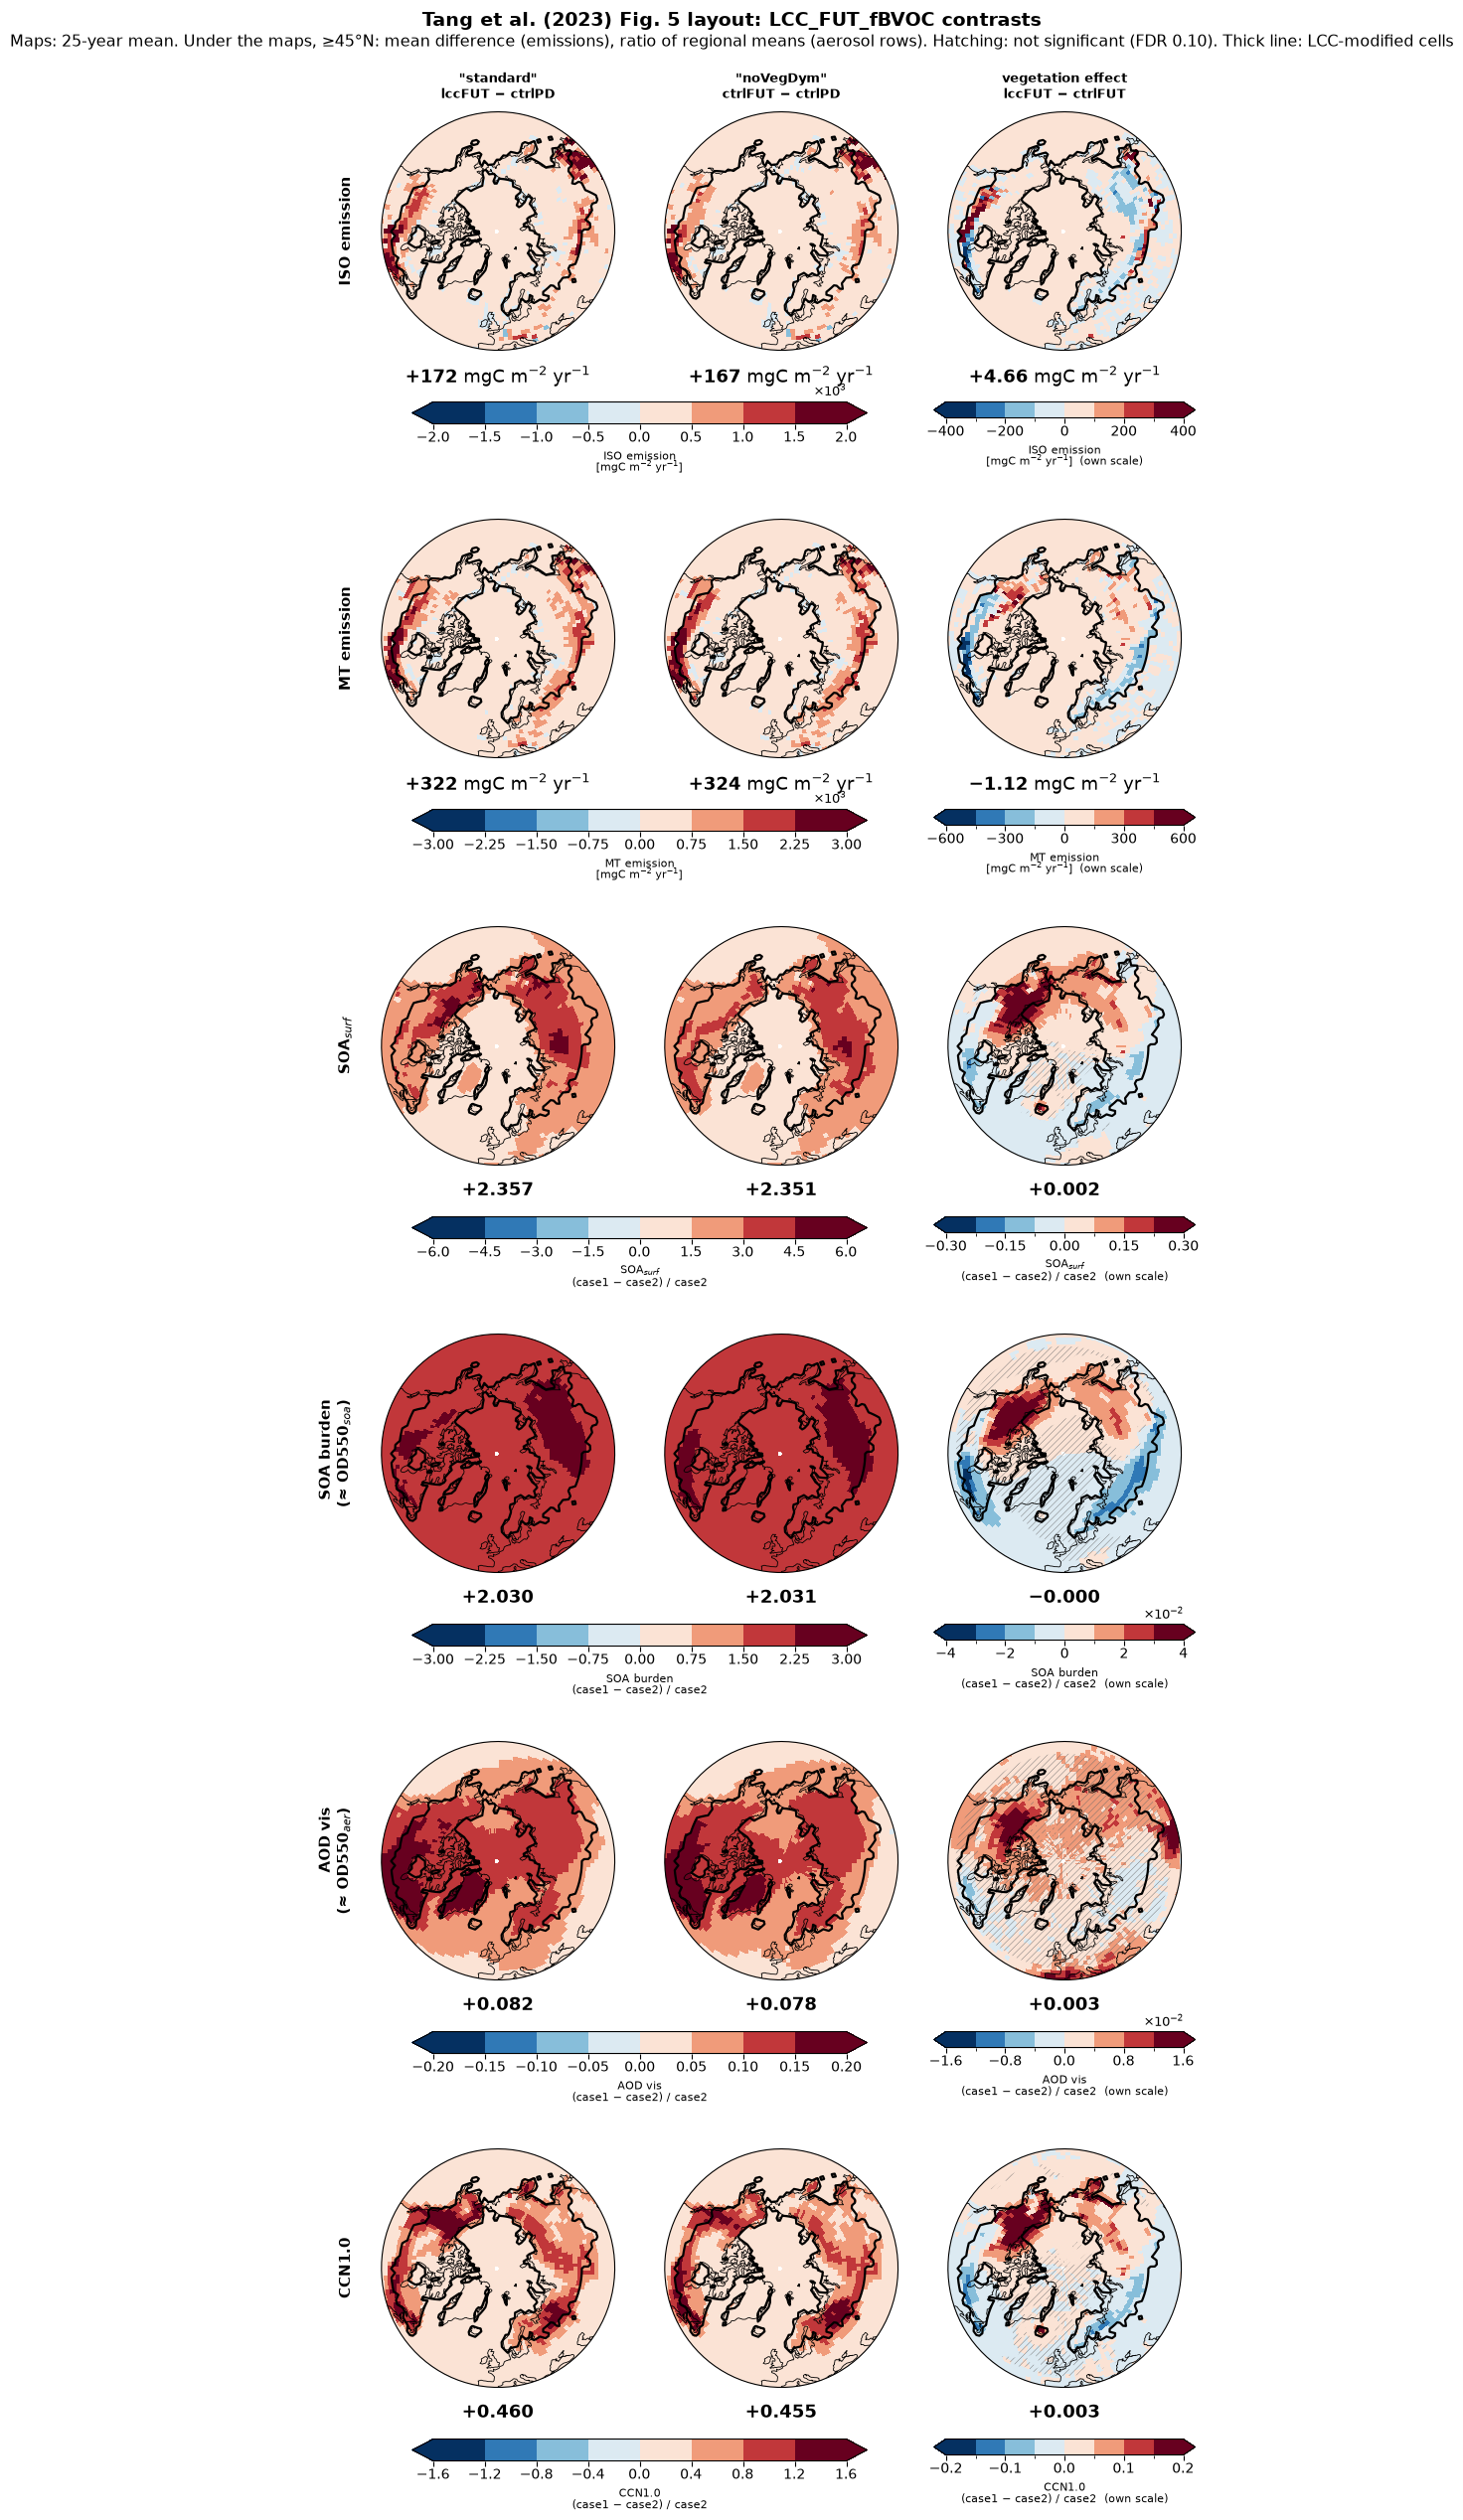

,row,column,case1,case2,kind,value_ge45N,value_modified_cells
0,ISO,std,LCC_FUT_fBVOClccFUT,LCC_FUT_fBVOCctrlPD,diff,171.621406,263.960847
1,ISO,noveg,LCC_FUT_fBVOCctrlFUT,LCC_FUT_fBVOCctrlPD,diff,166.956927,253.014710
2,ISO,veg,LCC_FUT_fBVOClccFUT,LCC_FUT_fBVOCctrlFUT,diff,4.664479,10.946137
3,MT,std,LCC_FUT_fBVOClccFUT,LCC_FUT_fBVOCctrlPD,diff,322.441296,529.524286
4,MT,noveg,LCC_FUT_fBVOCctrlFUT,LCC_FUT_fBVOCctrlPD,diff,323.560708,533.126306
5,MT,veg,LCC_FUT_fBVOClccFUT,LCC_FUT_fBVOCctrlFUT,diff,-1.119412,-3.602019
6,SOAs,std,LCC_FUT_fBVOClccFUT,LCC_FUT_fBVOCctrlPD,ratio,2.356868,NaN
7,SOAs,noveg,LCC_FUT_fBVOCctrlFUT,LCC_FUT_fBVOCctrlPD,ratio,2.350744,NaN
8,SOAs,veg,LCC_FUT_fBVOClccFUT,LCC_FUT_fBVOCctrlFUT,ratio,0.001828,NaN
9,SOAb,std,LCC_FUT_fBVOClccFUT,LCC_FUT_fBVOCctrlPD,ratio,2.029935,NaN


In [5]:
def vmax_of(maps, q=0.98):
    vals = np.concatenate([m.where(m["lat"] >= EXTENT_LAT).values.ravel() for m in maps])
    vals = np.abs(vals[np.isfinite(vals)])
    vals = vals[vals > 0]   # unmodified cells are exactly 0 in the vegetation column: leave them out
    return float(np.quantile(vals, q)) if vals.size else 1.0

# Discrete colour bars as in Tang Fig. 5: RdBu_r in equal bins, no white bin at 0, a tick on every bin edge
NICE = [1, 1.5, 2, 2.5, 3, 4, 5, 6, 7.5, 8, 10]

def nice_step(vmax, nside=4):
    raw = vmax / nside
    k = np.floor(np.log10(raw))
    m = raw / 10 ** k
    return next(n for n in NICE if n >= m - 1e-9) * 10 ** k

def discretize(p, vmax, nside):
    bounds = np.linspace(-vmax, vmax, 2 * nside + 1)
    cmap = plt.get_cmap("RdBu_r", 2 * nside)   # bin colours = RdBu_r resampled, ends = darkest
    cmap.set_over(cmap(cmap.N - 1)); cmap.set_under(cmap(0))
    p.set_cmap(cmap)
    p.set_norm(mcolors.BoundaryNorm(bounds, cmap.N))

from cartopy.util import add_cyclic_point

def outline_modified(ax, lw=1.6):
    """Thick black line around the LCC-modified cells."""
    data, lon_c = add_cyclic_point(modified.astype(float).values, coord=modified["lon"].values)
    ax.contour(lon_c, modified["lat"].values, data, levels=[0.5], colors="black", linewidths=lw,
               transform=ccrs.PlateCarree(), zorder=5)

def fmt_reg(v, kind):
    return f"{v:+.3g}" if kind == "diff" else f"{v:+.3f}"

def make_fig5(row_keys, fname, suptitle, limits=None):
    # limits: {row: (vmax, bins per side)} for columns 1-2 (e.g. Tang's); default: 98th percentile rounded to a nice step, 4 bins per side
    nrows, ncols = len(row_keys), 3
    fig, axes = fm.map_grid(nrows, ncols, left=1.25, titles_every_row=False, top_extra=0.45)
    table = []
    for i, key in enumerate(row_keys):
        f, label, units, kind = ROWS[key]
        res = {col: column_fields(key, col) for col in COLUMNS}
        if limits and key in limits:
            v_shared, n_shared = limits[key]
        else:
            n_shared = 4
            v_shared = n_shared * nice_step(vmax_of([res["std"][0], res["noveg"][0]]), n_shared)
        v_veg = 4 * nice_step(vmax_of([res["veg"][0]]), 4)   # column 3 always on its own scale
        mappables = {}
        for j, col in enumerate(COLUMNS):
            m, notsig, reg = res[col]
            vmax = v_veg if col == "veg" else v_shared
            p, norm, _ = fm.plot_single_boreal_panel(
                axes[i, j], m, COLUMNS[col][2] if i == 0 else "", units=units if kind == "diff" else "–",
                vmax=vmax, extent_lat=EXTENT_LAT, add_cbar=False, mean_lat_min=MEAN_LAT,
                sig=notsig, sig_style="lines", mean_text=fm._bold(fmt_reg(reg, kind)))
            discretize(p, vmax, 4 if col == "veg" else n_shared)
            outline_modified(axes[i, j])
            mappables[col] = p
            table.append(dict(row=key, column=col, case1=COLUMNS[col][0], case2=COLUMNS[col][1],
                              kind=kind, value_ge45N=reg,
                              value_modified_cells=(wmean(m, modified) if kind == "diff" else np.nan)))
        cbl = f"{label.splitlines()[0]}\n[{units}]" if kind == "diff" else f"{label.splitlines()[0]}\n(case1 − case2) / case2"
        fm._cbar_below(fig, axes[i, :2], mappables["std"], cbl, fm.CBAR_LABELSIZE_SHARED)
        cb = fm._cbar_below(fig, axes[i, 2], mappables["veg"], cbl + "  (own scale)", fm.CBAR_LABELSIZE,
                            shrink=fm.CBAR_SHRINK, height=fm.CBAR_HEIGHT)
        cb.set_ticks(mappables["veg"].norm.boundaries[::2])   # narrow bar: every other bin edge
        axes[i, 0].text(-0.12, 0.5, label, transform=axes[i, 0].transAxes, rotation=90,
                        ha="right", va="center", fontsize=11, fontweight="semibold")
    fm.add_suptitle(fig, suptitle, MEAN_LAT, subtitle=(f"Maps: {NYR}-year mean. Under the maps, ≥45°N: mean difference (emissions), "
                     "ratio of regional means (aerosol rows). Hatching: not significant (FDR 0.10). Thick line: LCC-modified cells"))
    fig.savefig(OUT / fname, dpi=200, bbox_inches="tight")
    plt.show()
    return pd.DataFrame(table)

OWN_LIMITS = {"SOAb": (3.0, 4)}   # SOA burden: bar to ±3 (the 98th percentile gave ±2.4, mostly saturated)
tab = make_fig5(list(ROWS), f"tang_fig5_layout_{Y0}_{Y1}.png",
                "Tang et al. (2023) Fig. 5 layout: LCC_FUT_fBVOC contrasts", limits=OWN_LIMITS)
tab

### 2b. Same figure on Tang's colour-bar ranges

Columns 1–2 use Tang's Fig. 5 standard/noVegDym bars exactly (range and number of bins) for the rows that are the **same quantity** as Tang's: ISO, MT, SOA_surf, CCN1.0. **SOA burden and AOD vis keep our own scale** (as in section 2): a ratio of SOA burden is not a ratio of SOA optical depth (OD550soa), and `AOD_VIS` is not exactly OD550aer, so Tang's numbers are not a like-for-like range for them. Column 3 keeps its own scale: Tang's third column is noCO2Inhibition, a different experiment, and on Tang's ranges our vegetation effect would be blank. Values beyond Tang's range fall in the end triangles.


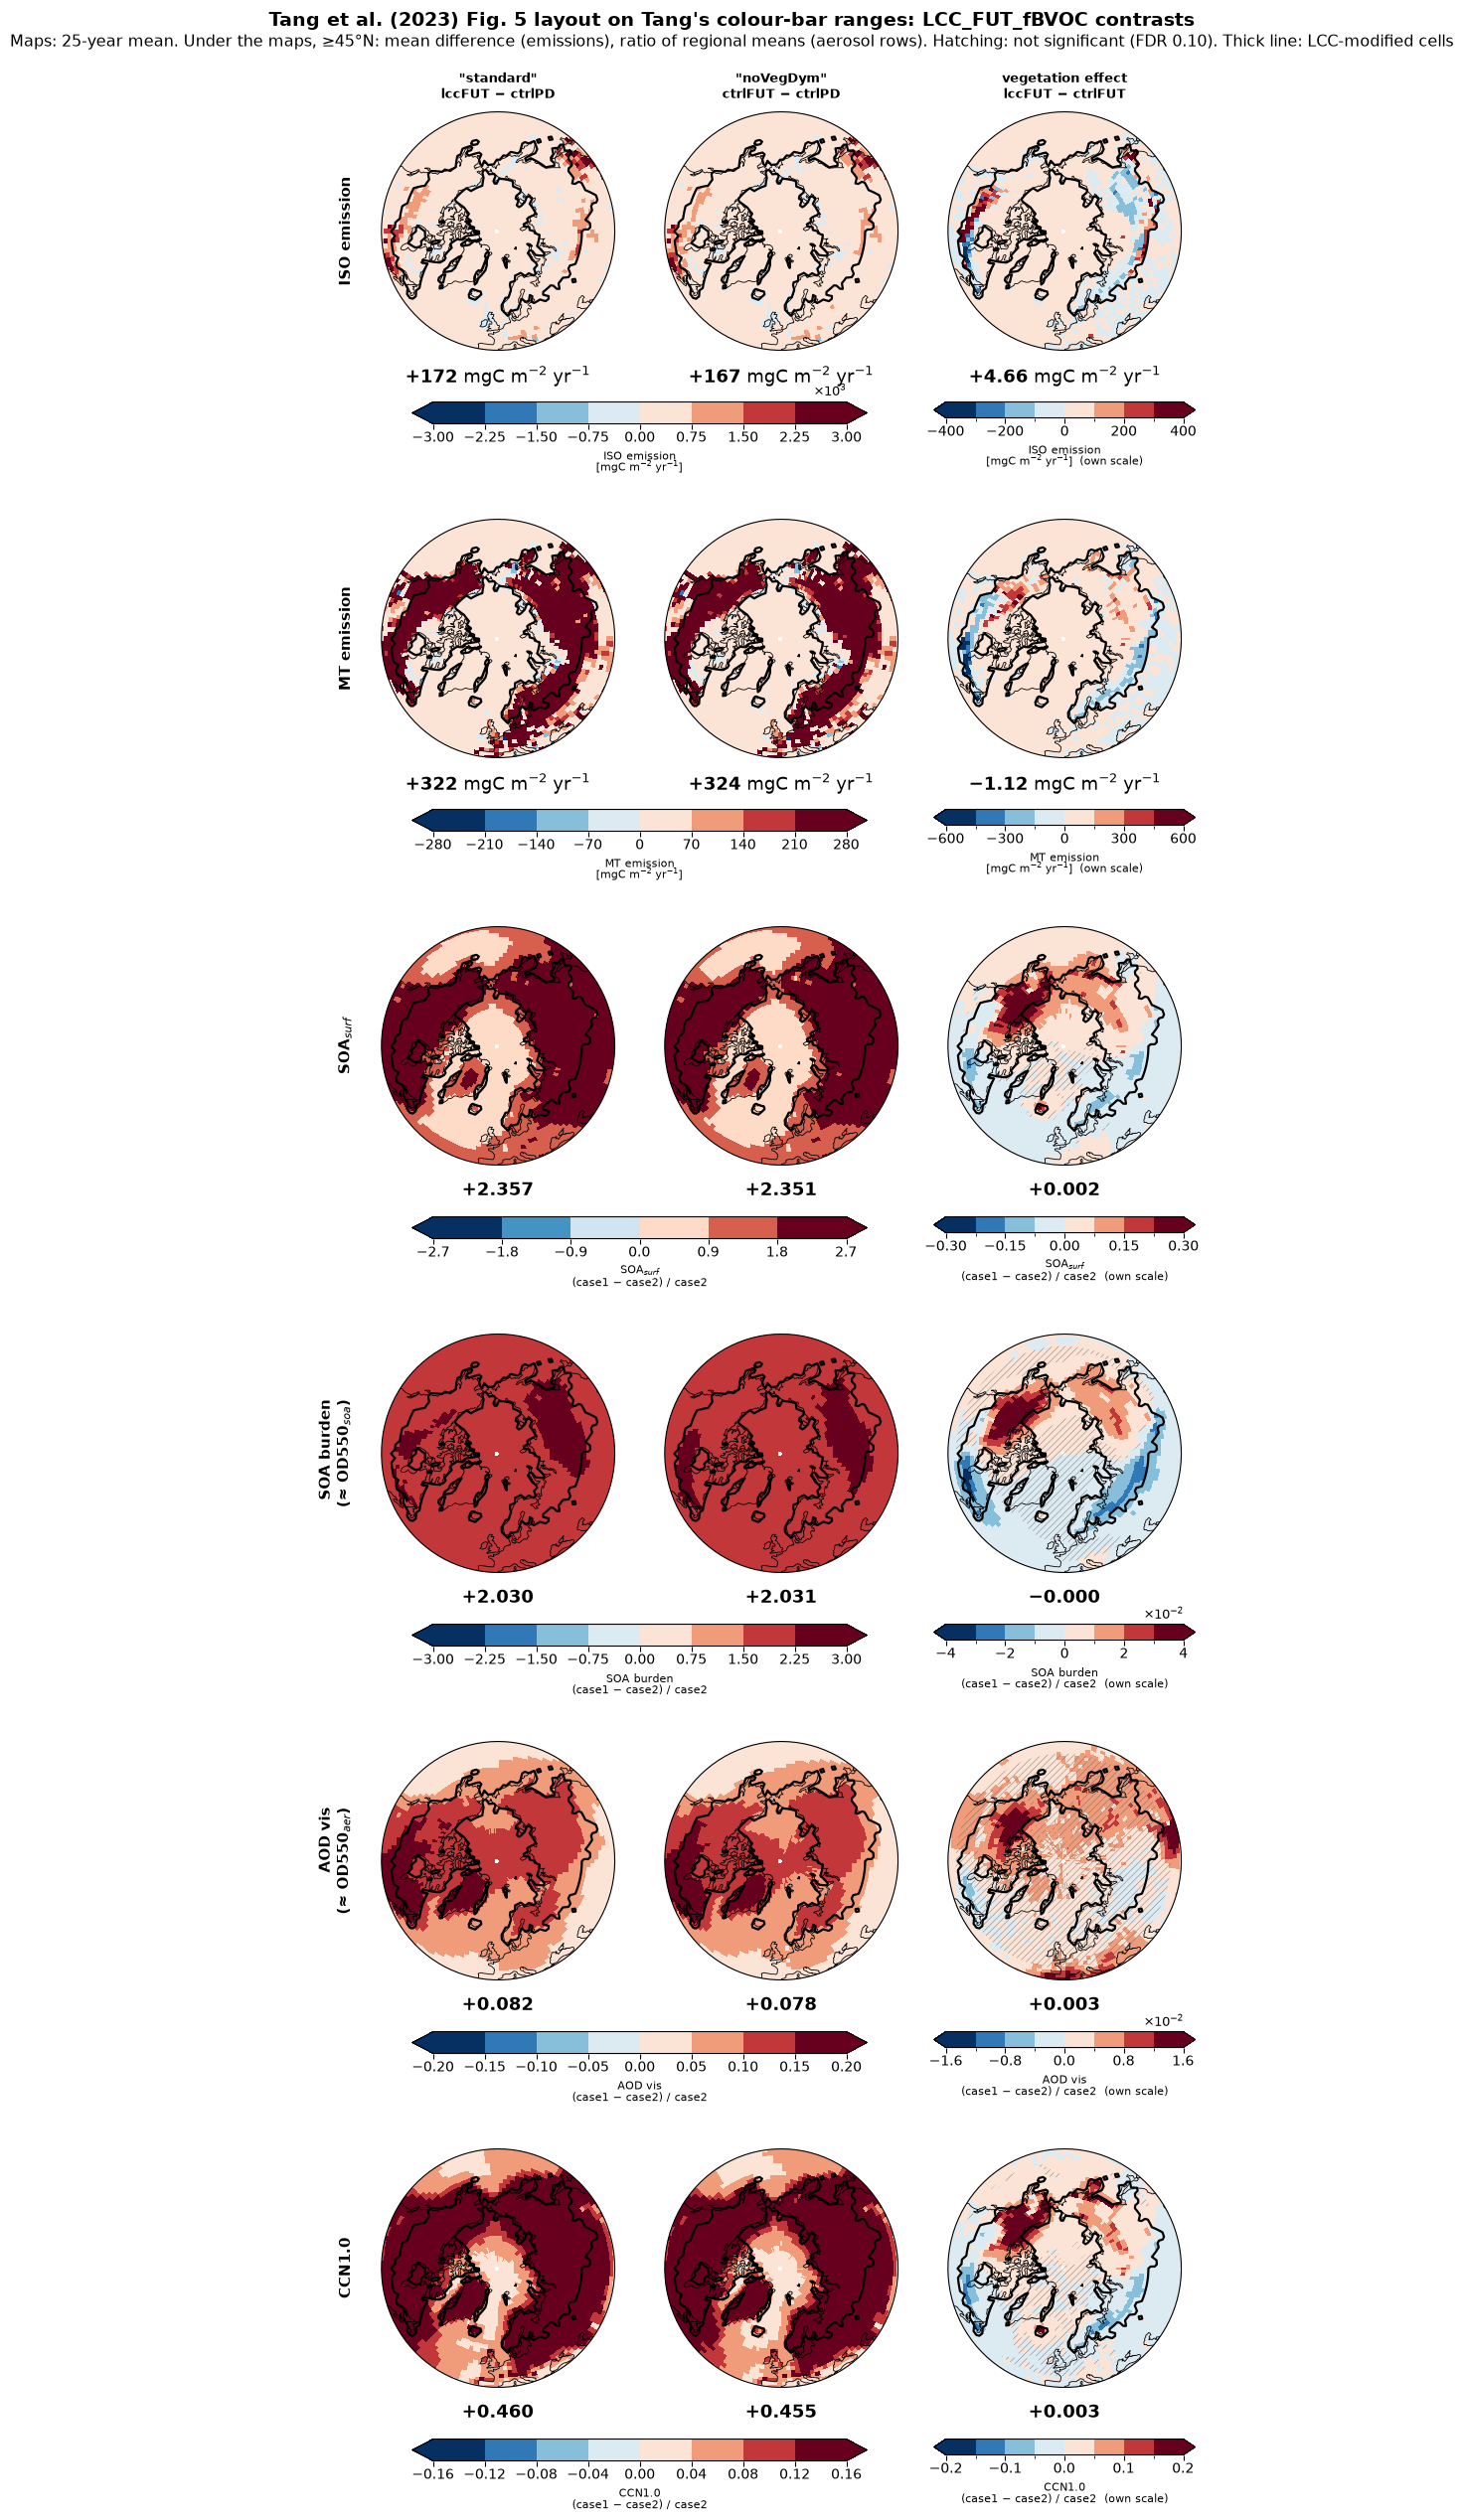

In [6]:
TANG_LIMITS = {   # Tang Fig. 5 a-b, d-e, g-h, j-k, m-n, p-q: (bar end, bins per side)
    "ISO": (3000, 4), "MT": (280, 4), "SOAs": (2.7, 3), "CCN": (0.16, 4),
}
# SOA burden and AOD_VIS are not Tang's OD550soa / OD550aer: they keep our own scale (same as section 2)
TANG_LIMITS.update(OWN_LIMITS)
_ = make_fig5(list(ROWS), f"tang_fig5_layout_tanglimits_{Y0}_{Y1}.png",
              "Tang et al. (2023) Fig. 5 layout on Tang's colour-bar ranges: LCC_FUT_fBVOC contrasts",
              limits=TANG_LIMITS)


## 3. Spatial pattern: regional boxes

Tang's monoterpene story (Figs. 1f, 2e, 5d): **decrease** where broadleaf deciduous trees replace boreal needleleaf trees (southern Fennoscandia, western Russia, southern boreal belt); **increase** where needleleaf trees move north (northern Canada, Siberia, Alaska). Boxes are rough land boxes, only modified cells counted. Emission changes in mgC m⁻² yr⁻¹ and relative to the case2 mean.

In [7]:
BOXES = {   # name: (lat0, lat1, lon0, lon1) with lon in 0-360
    "Fennoscandia + W Russia": (55, 70, 5, 60),
    "W Siberia": (55, 70, 60, 100),
    "E Siberia": (60, 75, 100, 180),
    "Alaska": (58, 72, 190, 220),
    "N Canada": (58, 72, 240, 300),
    "S boreal Canada": (46, 58, 240, 300),
}
lat, lon = modified["lat"], modified["lon"]
rows = []
for bname, (a0, a1, o0, o1) in BOXES.items():
    box = (lat >= a0) & (lat <= a1) & (lon >= o0) & (lon <= o1) & modified
    for key in ("ISO", "MT"):
        for col, (c1, c2, _) in COLUMNS.items():
            d = (yearly[c1, key] - yearly[c2, key]).mean("year")
            base = yearly[c2, key].mean("year")
            rows.append(dict(box=bname, n_cells=int(box.sum()), species=key, column=col,
                             diff=wmean(d, box), rel_pct=100 * wmean(d, box) / wmean(base, box)))
boxes = pd.DataFrame(rows)
box_tab = boxes.pivot_table(index=["box", "n_cells", "species"], columns="column", values=["diff", "rel_pct"])
box_tab = box_tab.reindex(columns=["std", "noveg", "veg"], level=1).round(1)
box_tab.to_csv(OUT / f"box_emission_changes_{Y0}_{Y1}.csv")
box_tab

diff                rel_pct         \
column                                      std   noveg    veg     std  noveg   
box                     n_cells species                                         
Alaska                  74      ISO       136.4   127.7    8.7   288.9  270.5   
                                MT        328.5   248.5   79.9   522.2  395.1   
E Siberia               218     ISO       147.5   172.5  -25.0   302.8  354.1   
                                MT        318.4   267.6   50.8   465.2  391.0   
Fennoscandia + W Russia 120     ISO       134.3   155.4  -21.1   126.5  146.4   
                                MT        522.7   579.3  -56.6   235.7  261.3   
N Canada                145     ISO       106.8    90.2   16.6   252.0  212.8   
                                MT        170.6   137.4   33.2   436.4  351.5   
S boreal Canada         111     ISO       602.2   525.8   76.4   189.6  165.6   
                                MT       1151.5  1315.2 -163.6   342.2  390.8   
W Siberia               121     ISO       440.2   422.9   17.3   285.8  274.5   
                                MT        745.2   793.3  -48.1   407.9  434.2   

                                               
column                                    veg  
box                     n_cells species        
Alaska                  74      ISO       5.0  
                                MT       25.7  
E Siberia               218     ISO     -11.3  
                                MT       15.1  
Fennoscandia + W Russia 120     ISO      -8.1  
                                MT       -7.1  
N Canada                145     ISO      12.5  
                                MT       18.8  
S boreal Canada         111     ISO       9.1  
                                MT       -9.9  
W Siberia               121     ISO       3.0  
                                MT       -4.9

## 4. Vegetation input: Tang Fig. 2 analogue

Change of natural-PFT cover (% of the grid cell = `PCT_NAT_PFT × PCT_NATVEG / 100`), LCC − CTRL surfdata, grouped like Tang's legend. CLM PFT indices: 1–3 needleleaf trees (1 temperate evergreen, 2 boreal evergreen, 3 boreal deciduous), 7–8 broadleaf deciduous trees (temperate, boreal), 9–11 shrubs, 12–13 C3 grasses (arctic, other). These are the only surfdata fields that differ (CLAUDE.md).

CTRL surfdata: /cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/release-clm5.0.18/surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c190304.nc
LCC surfdata:  /cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc


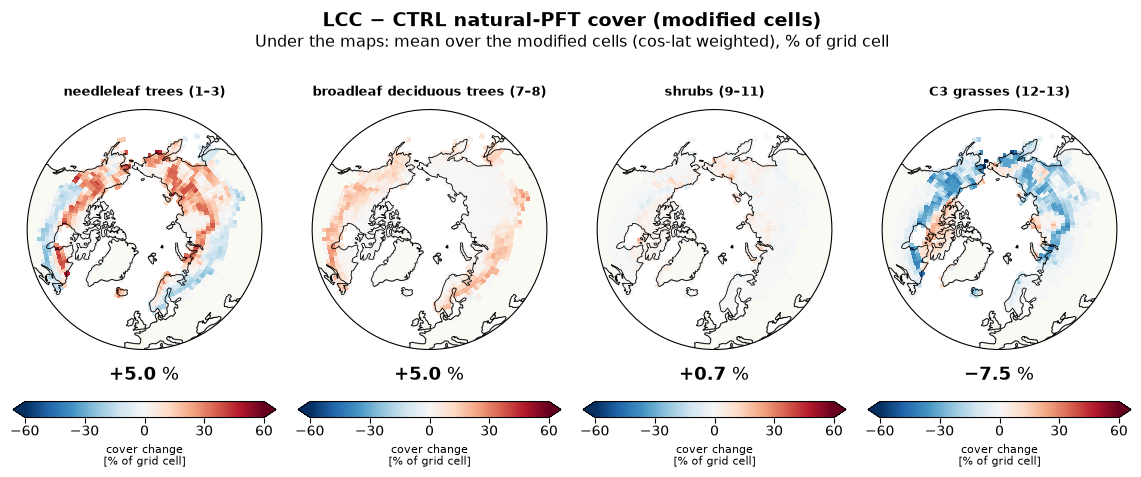

In [8]:
SURF = "/cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/"
s_ctrl = xr.open_dataset(SURF + "release-clm5.0.18/surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c190304.nc")
s_lcc = xr.open_dataset(SURF + "surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc")
print("CTRL surfdata:", mask_ds.attrs.get("baseline")); print("LCC surfdata: ", mask_ds.attrs.get("modified_source"))

def cover(s):
    c = s["PCT_NAT_PFT"] * s["PCT_NATVEG"] / 100
    return xr.DataArray(c.values, dims=("natpft", "lat", "lon"),
                        coords={"natpft": np.arange(c.sizes["natpft"]), "lat": lat.values, "lon": lon.values})
cv_ctrl, cv_lcc = cover(s_ctrl), cover(s_lcc)
GROUPS = {"needleleaf trees (1–3)": [1, 2, 3], "broadleaf deciduous trees (7–8)": [7, 8],
          "shrubs (9–11)": [9, 10, 11], "C3 grasses (12–13)": [12, 13]}

fig, axes = fm.map_grid(1, 4)
for ax, (g, idx) in zip(axes[0], GROUPS.items()):
    d = (cv_lcc.sel(natpft=idx).sum("natpft") - cv_ctrl.sel(natpft=idx).sum("natpft")).where(modified)
    fm.plot_single_boreal_panel(ax, d, g, units="%", vmax=60, extent_lat=EXTENT_LAT, mean_lat_min=MEAN_LAT,
                                cbar_label=f"cover change\n[% of grid cell]",
                                mean_text=fm._bold(f"{wmean(d.fillna(0), modified):+.1f}"))
fm.add_suptitle(fig, "LCC − CTRL natural-PFT cover (modified cells)", None,
                subtitle="Under the maps: mean over the modified cells (cos-lat weighted), % of grid cell")
fig.savefig(OUT / "pft_group_cover_change.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Emission totals: Tang Fig. 1d, h analogue

Tang Fig. 1d, h, over the RESOLVE tundra + boreal biomes, **read off the figure by eye** (±0.3 TgC yr⁻¹ ISO, ±0.1 MT). Historical (2000–2014, black line): ISO ≈ 12.5, MT ≈ 4.85 TgC yr⁻¹. Around 2100, the solid line = **mean of the 5 SSPs** (SSP585 alone is not plotted; error bars = Tang's min–max shading over the SSPs): GFDL-ESM4 ISO ≈ 14.7 (13.4–16.2), MT ≈ 4.6 (3.6–5.3); CanESM5 ISO ≈ 20.5 (19–24), MT ≈ 5.5 (5.0–6.0). GFDL-ESM4 is our LCC source; CanESM5 drives Tang's Fig. 5. Under SSP5-8.5 alone (GFDL) the MT drop is larger (Fig. 3 and Supp. Fig. 9: CO₂ inhibition dominates). Our region is not the same: we use the LCC-modified cells (46–82°N land touched by the LPJ-GUESS cover) and all land ≥45°N. Area from the model `gw` weights.

modified cells        land ≥45°N       
                                            ISO     MT        ISO     MT
CTRL_PD veg, PD climate (ctrlPD)           3.64   4.39       8.25   7.35
CTRL veg, FUT climate (ctrlFUT)           11.01  19.92      20.47  31.03
LCC veg, FUT climate (lccFUT)             11.33  19.81      20.81  30.95

findfont: Failed to find font weight semibold, now using 700.


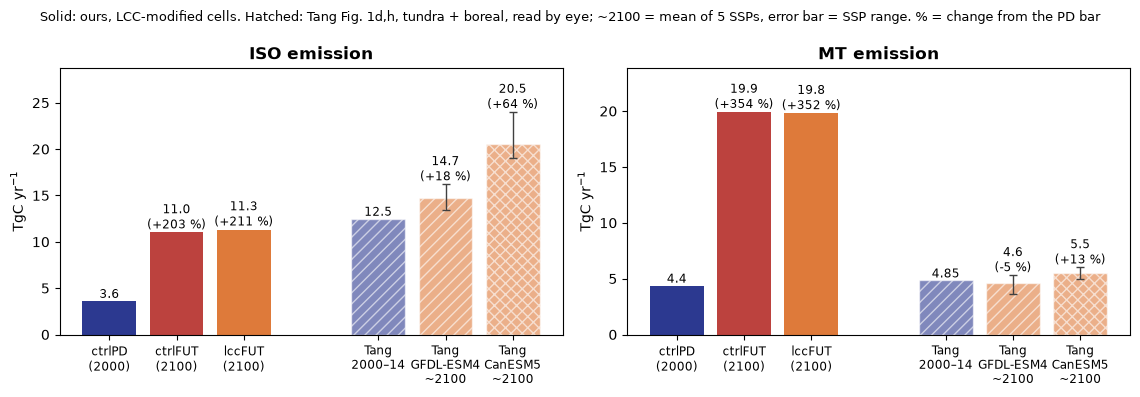

In [9]:
R = 6.37122e6
ds0 = cached[RUNS[0]]
dlon = np.deg2rad(float(ds0["lon"][1] - ds0["lon"][0]))
area = (R**2 * dlon * ds0["gw"]).broadcast_like(modified)   # m2; gw sums to 2
land45 = (ds0["LANDFRAC"].isel(time=0) > 0) & region

def total_TgC(run, key, where):
    flux = yearly[run, key].mean("year")              # mgC m-2 yr-1
    return float((flux * area).where(where).sum()) * 1e-15   # mg -> Tg

EMS = {"CTRL_PD veg, PD climate (ctrlPD)": "LCC_FUT_fBVOCctrlPD",
       "CTRL veg, FUT climate (ctrlFUT)": "LCC_FUT_fBVOCctrlFUT",
       "LCC veg, FUT climate (lccFUT)": "LCC_FUT_fBVOClccFUT"}
tot = pd.DataFrame({(reg, key): {lab: total_TgC(run, key, w) for lab, run in EMS.items()}
                    for reg, w in [("modified cells", modified), ("land ≥45°N", land45)] for key in ("ISO", "MT")})
tot.to_csv(OUT / f"emission_totals_TgC_{Y0}_{Y1}.csv")
display(tot.round(2))

TANG_TOT = {   # Tang Fig. 1d,h by eye: historical 2000-2014; ~2100: 5-SSP mean (min, max of the SSP shading)
    "ISO": {"hist": 12.5, "GFDL-ESM4": (14.7, 13.4, 16.2), "CanESM5": (20.5, 19.0, 24.0)},
    "MT":  {"hist": 4.85, "GFDL-ESM4": (4.6, 3.6, 5.3), "CanESM5": (5.5, 5.0, 6.0)},
}
cols = [pal.NAVY, pal.RED, pal.ORANGE]   # ctrlPD, ctrlFUT, lccFUT; Tang historical = ctrlPD colour, Tang ~2100 (veg + climate) = lccFUT colour

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.0))
for ax, key in zip(axs, ("ISO", "MT")):
    vals = tot[("modified cells", key)].values
    ax.bar(range(3), vals, color=cols)
    for x, v in zip(range(3), vals):
        ax.text(x, v, f"{v:.1f}" if x == 0 else f"{v:.1f}\n({100 * (v / vals[0] - 1):+.0f} %)",
                ha="center", va="bottom", fontsize=8.5)
    t = TANG_TOT[key]
    ax.bar(4, t["hist"], color=cols[0], hatch="///", edgecolor="white", alpha=0.6)
    ax.text(4, t["hist"], f"{t['hist']:g}", ha="center", va="bottom", fontsize=8.5)
    for x, gcm, hatch in [(5, "GFDL-ESM4", "///"), (6, "CanESM5", "xxx")]:
        m, lo, hi = t[gcm]
        ax.bar(x, m, color=cols[2], hatch=hatch, edgecolor="white", alpha=0.6)
        ax.errorbar(x, m, yerr=[[m - lo], [hi - m]], fmt="none", ecolor="0.25", capsize=3, lw=1)
        ax.text(x, hi, f"{m:g}\n({100 * (m / t['hist'] - 1):+.0f} %)", ha="center", va="bottom", fontsize=8.5)
    ax.set_xticks([0, 1, 2, 4, 5, 6], ["ctrlPD\n(2000)", "ctrlFUT\n(2100)", "lccFUT\n(2100)",
                                       "Tang\n2000–14", "Tang\nGFDL-ESM4\n~2100", "Tang\nCanESM5\n~2100"], fontsize=8.5)
    ax.set_ylim(0, 1.2 * max(vals.max(), t["CanESM5"][2]))
    ax.set_title(f"{key} emission", fontweight="semibold")
    ax.set_ylabel("TgC yr$^{-1}$")
fig.suptitle("Solid: ours, LCC-modified cells. Hatched: Tang Fig. 1d,h, tundra + boreal, read by eye; "
             "~2100 = mean of 5 SSPs, error bar = SSP range. % = change from the PD bar", fontsize=9.5)
fig.tight_layout()
fig.savefig(OUT / f"emission_totals_vs_tang_{Y0}_{Y1}.png", dpi=200, bbox_inches="tight")
plt.show()


## 5b. Emission trend maps: Tang Fig. 1b, f analogue

Tang Fig. 1b, f: per-cell **linear trend** of ISO and MT emission over 2001–2100, SSP585, mean of 3 GCMs (LPJ-GUESS), only significant cells (Mann–Kendall p < 0.05), in **mgC m⁻² yr⁻²**. We have two time slices, not a time series, so our "trend" is **(2100 − 2000) / 100 yr**: `(LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlPD) / 100`, i.e. Tang's "standard" change (vegetation + climate + CO₂). For a linear change the two agree; otherwise ours only shows the sign and the size of the end-to-end change. "2000" = the CTRL_PD 2001–2014 emission climatology (year-2000 forcing), "2100" = the LCC_FUT one. No significance test (emissions are a climatology). Colour ranges as Tang's colour bars (read by eye; Tang's maps are continuous, so ours are too). **Three columns:** (1) Tang's "standard" change (vegetation + climate + CO₂), as above; (2) **vegetation only, FUT background**: `LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlFUT` (LCC vs CTRL vegetation, both under the FUT climate); (3) **vegetation only, PD background**: `LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD` (both PD climate). Columns 2–3 are also divided by 100 yr: the part of the 2000→2100 change per year that the vegetation change alone gives, if the LPJ-GUESS cover change is spread over the century. Right: distribution of the per-cell values in the LCC-modified cells (as Tang Fig. 1c, g, but a histogram, not a kernel fit, and with all cells, not only significant ones).


findfont: Failed to find font weight semibold, now using 700.


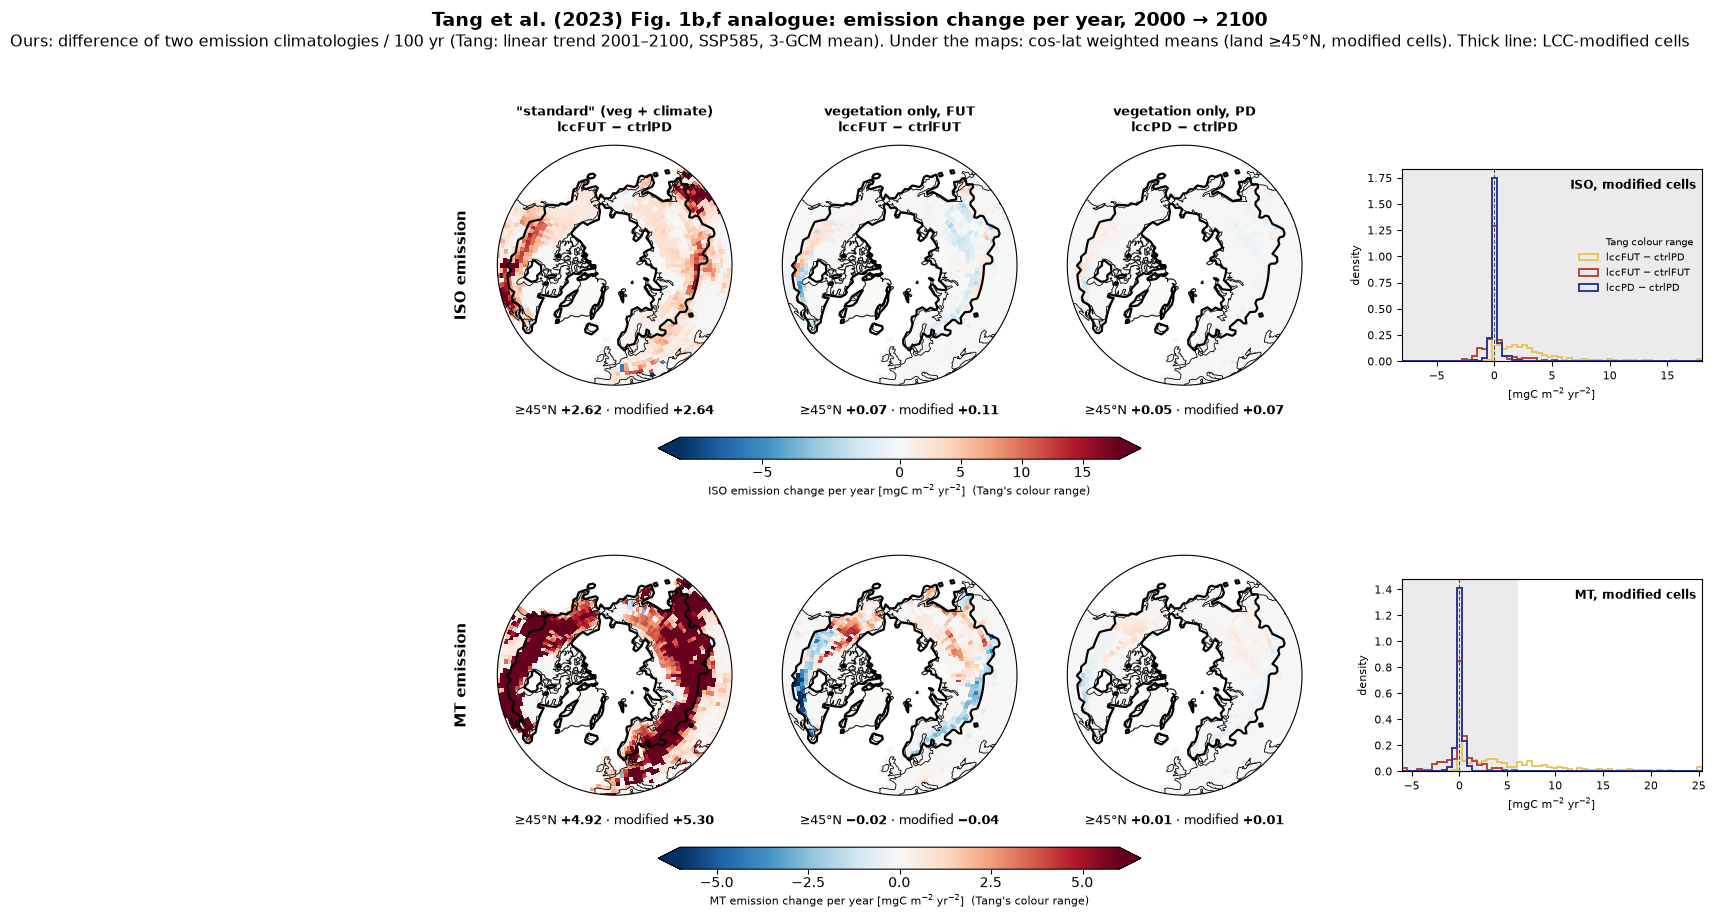

mean_land_ge45N  mean_modified  \
species contrast                                   
ISO     std                 2.616          2.640   
        vegFUT              0.071          0.109   
        vegPD               0.053          0.073   
MT      std                 4.916          5.295   
        vegFUT             -0.017         -0.036   
        vegPD               0.011          0.011   

                  frac_modified_cells_decreasing  
species contrast                                  
ISO     std                                0.101  
        vegFUT                             0.385  
        vegPD                              0.289  
MT      std                                0.091  
        vegFUT                             0.319  
        vegPD                              0.285

In [10]:
DT_YR = 100.0   # 2000 -> 2100
TANG_TREND_LIM = {"ISO": (-8.0, 18.0, [-5, 0, 5, 10, 15]), "MT": (-6.0, 6.0, [-5, -2.5, 0, 2.5, 5])}   # Tang Fig. 1b,f bars, by eye
TREND_COLS = {   # key: (case1, case2, title, histogram colour)
    "std":    ("LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlPD", "\"standard\" (veg + climate)\nlccFUT − ctrlPD", pal.GOLD),
    "vegFUT": ("LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlFUT", "vegetation only, FUT\nlccFUT − ctrlFUT", pal.RED),
    "vegPD":  ("LCC_PD_fBVOClccPD", "LCC_PD_fBVOCctrlPD", "vegetation only, PD\nlccPD − ctrlPD", pal.NAVY),
}
land = ds0["LANDFRAC"].isel(time=0) > 0

fig, axes = fm.map_grid(2, 3, left=1.25, titles_every_row=False, top_extra=0.45)
W, H = fig.get_figwidth(), fig.get_figheight()
trend_tab = []
for i, key in enumerate(("ISO", "MT")):
    lo, hi, ticks = TANG_TREND_LIM[key]
    trs = {}
    for j, (col, (c1, c2, title, colr)) in enumerate(TREND_COLS.items()):
        a, b = yearly[c1, key].mean("year"), yearly[c2, key].mean("year")
        tr = ((a - b) / DT_YR).where(land & ((a != 0) | (b != 0)))   # mgC m-2 yr-2, land with emissions
        trs[col] = tr
        m45, mmod = wmean(tr.fillna(0), land & region), wmean(tr.fillna(0), modified)
        trend_tab.append(dict(species=key, contrast=col, case1=c1, case2=c2, mean_land_ge45N=m45, mean_modified=mmod,
                              frac_modified_cells_decreasing=float((tr.where(modified) < 0).sum() / tr.where(modified).notnull().sum())))
        p, _, _ = fm.plot_single_boreal_panel(
            axes[i, j], tr, title if i == 0 else "", units="–", vmax=hi, extent_lat=EXTENT_LAT, add_cbar=False,
            mean_lat_min=MEAN_LAT, mean_fontsize=9,
            mean_text=f"≥45°N {fm._bold(f'{m45:+.2f}')} · modified {fm._bold(f'{mmod:+.2f}')}")
        p.set_norm(mcolors.TwoSlopeNorm(vmin=lo, vcenter=0.0, vmax=hi))
        outline_modified(axes[i, j])
    cb = fm._cbar_below(fig, axes[i, :], p, f"{key} emission change per year [mgC m$^{{-2}}$ yr$^{{-2}}$]  (Tang's colour range)",
                        fm.CBAR_LABELSIZE_SHARED, shrink=0.6)
    cb.set_ticks(ticks)
    axes[i, 0].text(-0.12, 0.5, f"{key} emission", transform=axes[i, 0].transAxes, rotation=90,
                    ha="right", va="center", fontsize=11, fontweight="semibold")
    # histogram over the modified cells, right of the row
    bpos = axes[i, 2].get_position()
    ax = fig.add_axes([bpos.x1 + 1.0 / W, bpos.y0 + 0.1 * bpos.height, 3.0 / W, 0.8 * bpos.height])
    allv = np.concatenate([t.where(modified).values.ravel() for t in trs.values()]); allv = allv[np.isfinite(allv)]
    xlo, xhi = min(lo, np.quantile(allv, 0.005)), max(hi, np.quantile(allv, 0.995))
    bins = np.linspace(xlo, xhi, 61)
    ax.axvspan(lo, hi, color="0.92", zorder=0, label="Tang colour range")
    for col, (*_, title, colr) in TREND_COLS.items():
        v = trs[col].where(modified).values.ravel(); v = v[np.isfinite(v)]
        ax.hist(np.clip(v, xlo, xhi), bins=bins, density=True, histtype="step", color=colr, lw=1.4,
                label=title.split("\n")[1])
    ax.axvline(0, color="0.3", ls="--", lw=0.8)
    ax.set_xlim(xlo, xhi); ax.set_ylabel("density", fontsize=8); ax.tick_params(labelsize=8)
    ax.set_xlabel("[mgC m$^{-2}$ yr$^{-2}$]", fontsize=8)
    ax.text(0.98, 0.95, f"{key}, modified cells", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, fontweight="semibold")
    if i == 0:
        ax.legend(fontsize=7, frameon=False, loc="center right")
fm.add_suptitle(fig, "Tang et al. (2023) Fig. 1b,f analogue: emission change per year, 2000 → 2100", None,
                subtitle="Ours: difference of two emission climatologies / 100 yr (Tang: linear trend 2001–2100, SSP585, 3-GCM mean). "
                         "Under the maps: cos-lat weighted means (land ≥45°N, modified cells). Thick line: LCC-modified cells")
fig.savefig(OUT / f"tang_fig1bf_trend_maps_{Y0}_{Y1}.png", dpi=200, bbox_inches="tight")
plt.show()
trend_tab = pd.DataFrame(trend_tab).set_index(["species", "contrast"])
trend_tab.to_csv(OUT / f"fig1bf_trend_values_{Y0}_{Y1}.csv")
trend_tab.drop(columns=["case1", "case2"]).round(3)


## 6. Numbers side by side

Tang values from the text and Fig. 5 colour bars (CanESM5 SSP585, **maxima** "up to", not regional means). Ours: ≥45°N ratio of regional means (aerosol rows) from section 2.

In [11]:
pick = lambda r, c: float(tab.query("row == @r and column == @c")["value_ge45N"].iloc[0])
side = pd.DataFrame([
    ("SOA_surf ratio", "up to +2.7 (std; Fig. 5g)", "much smaller, Canada patch (Fig. 5h)", pick("SOAs", "std"), pick("SOAs", "noveg"), pick("SOAs", "veg")),
    ("OD550soa ratio (ours: SOA burden)", "+0.29 (std; text)", "small, central/E Canada (Fig. 5k)", pick("SOAb", "std"), pick("SOAb", "noveg"), pick("SOAb", "veg")),
    ("OD550aer ratio (ours: AOD_VIS)", "+0.041 (std; text)", "small (Fig. 5n)", pick("AOD", "std"), pick("AOD", "noveg"), pick("AOD", "veg")),
    ("CCN1.0 ratio", "mostly ±0.04, +0.16 max (Fig. 5p)", "±0.04 (Fig. 5q)", pick("CCN", "std"), pick("CCN", "noveg"), pick("CCN", "veg")),
], columns=["quantity", "Tang standard", "Tang noVegDym", "ours std (≥45°N)", "ours noVegDym (≥45°N)", "ours veg effect (≥45°N)"])
side.to_csv(OUT / f"side_by_side_{Y0}_{Y1}.csv", index=False)
tab.to_csv(OUT / f"fig5_layout_values_{Y0}_{Y1}.csv", index=False)
side

,quantity,Tang standard,Tang noVegDym,ours std (≥45°N),ours noVegDym (≥45°N),ours veg effect (≥45°N)
0,SOA_surf ratio,up to +2.7 (std; Fig. 5g),"much smaller, Canada patch (Fig. 5h)",2.356868,2.350744,0.001828
1,OD550soa ratio (ours: SOA burden),+0.29 (std; text),"small, central/E Canada (Fig. 5k)",2.029935,2.030655,-0.000238
2,OD550aer ratio (ours: AOD_VIS),+0.041 (std; text),small (Fig. 5n),0.081886,0.078443,0.003192
3,CCN1.0 ratio,"mostly ±0.04, +0.16 max (Fig. 5p)",±0.04 (Fig. 5q),0.459683,0.455219,0.003067


## 7. Reading the results (2026-11-17, run 2001–2025)

Evidence tags: **(a)** read from the outputs above, **(b)** inference, **(c)** unverified.

**1. Spatial pattern of the vegetation effect: same as Tang for monoterpenes (a).** Column 3 and the box table: MT **decreases** where broadleaf deciduous trees replace needleleaf trees (southern boreal Canada −10 %, Fennoscandia + W Russia −7 %, W Siberia −5 %) and **increases** where needleleaf trees move north (Alaska +26 %, N Canada +19 %, E Siberia +15 %). The PFT maps (section 4) show that cover change: needleleaf +, grasses − in the north; broadleaf deciduous + and needleleaf − in the southern belt. This is Tang's Fig. 1f / 2e / 5d story.

**2. Isoprene goes the other way in places (a); cause not checked (b).** Vegetation effect on ISO: Fennoscandia + W Russia −8 %, E Siberia −11 %, but N Canada +13 %, S boreal Canada +9 %. In Tang the broadleaf replacement *raises* isoprene. Possible reasons (b): how CLM-MEGAN assigns isoprene emission factors to boreal broadleaf deciduous trees, and the grass loss (grasses emit isoprene in Tang too).

**3. Size: our vegetation effect is ~1 % of the climate effect (a).** ≥45°N ratios:

| | standard | noVegDym | vegetation | Tang standard (CanESM5 SSP585) |
|---|---|---|---|---|
| SOA_surf | +2.36 | +2.35 | +0.002 | up to +2.7 (max) |
| SOA burden (≈ OD550soa) | +2.03 | +2.03 | −0.0002 | +0.29 |
| AOD_VIS (≈ OD550aer) | +0.082 | +0.078 | +0.003 | +0.041 |
| CCN1.0 | +0.46 | +0.46 | +0.003 | mostly ±0.04 |

Locally the vegetation effect is not negligible: SOA_surf up to about +0.28 over northern Canada (colour-bar 98th percentile), significant there.

**4. Our climate-driven change is much bigger than Tang's (a), consistent with MEGAN having no monoterpene CO₂ inhibition (b).** Modified cells: ISO 3.6 → 11.0 TgC yr⁻¹ (×3), MT 4.4 → 19.9 TgC yr⁻¹ (×4.5) from ctrlPD to ctrlFUT emissions. Tang (Fig. 1d,h, by eye, mean of 5 SSPs, ~2100 vs 2000–2014): GFDL-ESM4 ISO ≈ +18 %, MT ≈ −5 %; CanESM5 (the warmest GCM) ISO ≈ +64 %, MT ≈ +13 % (corrected 2026-11-19; before: GFDL +7 % / −10 %, misread). So our "standard" SOA burden (+203 %) and CCN1.0 (+46 %) are far above Tang's (+29 %, ±4 %). The NorESM2 2100 climate is also not GFDL-ESM4's (b).

**5. Present-day totals (c: regions differ).** MT in the modified cells (4.4 TgC yr⁻¹) is close to Tang's ~5 TgC yr⁻¹ over tundra + boreal; ISO is lower (3.6 modified cells, 8.2 all land ≥45°N, vs ~12.5 historical).

**Bottom line (b).** The LPJ-GUESS cover change gives the *pattern* Tang describes (monoterpene dipole, SOA up over northern Canada), but in our set-up it is a ~1 % perturbation on top of a climate-driven emission increase that is several times larger than in LPJ-GUESS. The difference comes from (i) only PFT fractions being swapped (no LPJ-GUESS LAI/productivity) and (ii) MEGAN's temperature response without monoterpene CO₂ inhibition.